# GLMを指数型分布族から導出する

## 概要

一般化線形モデル（GLM）を指数型分布族から導く。正規・ベルヌーイ・ポアソン分布を同じ形に書き直し、最尤推定を反復重み付き最小二乗法（IRLS）につなげる。最後に人工データでポアソン回帰を計算する。

## 実行環境

カーネルは `wa-src(3.14.6)`、Pythonは `3.14.6` である。以下にライブラリのバージョンを表示する。セルは上から実行する。図はノートブックと同じ階層の `102_nb_files` にSVGで保存する。

In [1]:
import platform
import sys
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import numpy as np
import scipy
from scipy.optimize import minimize
from scipy.special import expit, gammaln
from scipy.stats import bernoulli, norm, poisson
import sympy as sp
from IPython.display import Latex, SVG, display

assert sys.version_info[:3] == (3, 14, 6), 'Python 3.14.6 のカーネルを選択する'
print(f'環境: wa-src({platform.python_version()})')
print(f'OS: {platform.system()} / {platform.machine()}')
for name, module in [('NumPy', np), ('SciPy', scipy),
                     ('Matplotlib', matplotlib), ('SymPy', sp)]:
    print(f'{name}: {module.__version__}')

image_dir = Path('102_nb_files')
image_dir.mkdir(exist_ok=True)

# 計算精度は変えず、出力するときだけ有効数字3桁に整える。
def sig3(value):
    text = f'{float(value):#.3g}'
    return text[:-1] if text.endswith('.') else text


np.set_printoptions(formatter={'float_kind': sig3})
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'svg.fonttype': 'path',
})


def save_svg(fig, filename):
    # 小数の目盛も3桁にそろえ、SVGを保存して出力欄に表示する。
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: sig3(x)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: sig3(y)))
        ax.grid(alpha=0.200)
    path = image_dir / filename
    fig.savefig(path, format='svg', bbox_inches='tight')
    plt.close(fig)
    display(SVG(filename=str(path)))

環境: wa-src(3.14.6)
OS: Darwin / arm64
NumPy: 2.5.4
SciPy: 1.18.1
Matplotlib: 3.11.2
SymPy: 1.14.0


## 1. 正規化条件から平均と分散を求める

ここでは応答$y$が次の形で現れる指数型分布族を扱う。$\theta$は自然パラメータ、$\phi>0$は分散パラメータ、$b$は正規化を担う関数である。

<div>

$$
f(y;\theta,\phi)=\exp\left\{\frac{y\theta-b(\theta)}{\phi}+c(y,\phi)\right\}.
$$

</div>

$\phi$を固定し、台が$\theta$に依存せず、微分と積分を交換できると仮定する。離散分布では積分を和に置き換える。まず正規化条件を一回微分する。

$$
\begin{aligned}
\int f(y;\theta,\phi)\,dy&=1,\\
\frac{\partial f}{\partial\theta}&=f\frac{y-b'(\theta)}{\phi},\\
0=\int\frac{\partial f}{\partial\theta}\,dy
&=\frac{E[Y]-b'(\theta)}{\phi}.
\end{aligned}
$$

したがって$\mu=E[Y]=b'(\theta)$である。もう一回微分すると、

$$
\begin{aligned}
\frac{\partial^2 f}{\partial\theta^2}
&=f\left\{\frac{(y-b'(\theta))^2}{\phi^2}-\frac{b''(\theta)}{\phi}\right\},\\
0=\int\frac{\partial^2 f}{\partial\theta^2}\,dy
&=\frac{E[(Y-\mu)^2]}{\phi^2}-\frac{b''(\theta)}{\phi},\\
\operatorname{Var}(Y)&=\phi b''(\theta).
\end{aligned}
$$

平均と分散は$b$の微分で決まる。私は分布ごとの式を覚えるより、この関係から確認する方が整理しやすいと感じる。

In [2]:
# 重要な関係をLaTeXの出力としても表示する。
display(Latex(r'\(\displaystyle \mu=b^{\prime}(\theta),\qquad '
              r'\operatorname{Var}(Y)=\phi b^{\prime\prime}(\theta)\)'))

# 3分布のbを記号微分し、平均と「分散 / phi」を確認する。
theta = sp.Symbol('theta', real=True)
cumulants = {
    'Normal': theta**2 / 2,
    'Bernoulli': sp.log(1 + sp.exp(theta)),
    'Poisson': sp.exp(theta),
}
for name, b in cumulants.items():
    first = sp.diff(b, theta)
    second = sp.simplify(sp.diff(first, theta))
    print(name)
    display(Latex(
        r'\(\displaystyle b(\theta)=' + sp.latex(b)
        + r',\quad b^{\prime}(\theta)=' + sp.latex(first)
        + r',\quad b^{\prime\prime}(\theta)=' + sp.latex(second) + r'\)'
    ))

<IPython.core.display.Latex object>

Normal


<IPython.core.display.Latex object>

Bernoulli


<IPython.core.display.Latex object>

Poisson


<IPython.core.display.Latex object>

## 2. 三つの分布を書き直す

正規分布$N(\mu,\sigma^2)$では平方を展開する。

$$
\begin{aligned}
\log f(y)&=-\frac{(y-\mu)^2}{2\sigma^2}-\frac12\log(2\pi\sigma^2)\\
&=\frac{y\mu-\mu^2/2}{\sigma^2}-\frac{y^2}{2\sigma^2}-\frac12\log(2\pi\sigma^2).
\end{aligned}
$$

ベルヌーイ分布では$y\in\{0,1\}$、$0<p<1$である。$\theta=\log\{p/(1-p)\}$と置くと$p=e^\theta/(1+e^\theta)$となる。

$$
\begin{aligned}
\log f(y)&=y\log p+(1-y)\log(1-p)\\
&=y\log\frac{p}{1-p}+\log(1-p)\\
&=y\theta-\log(1+e^\theta).
\end{aligned}
$$

ポアソン分布では$y=0,1,\ldots$、$\lambda>0$である。$\theta=\log\lambda$と置く。

$$
\begin{aligned}
f(y)&=\frac{e^{-\lambda}\lambda^y}{y!},\\
\log f(y)&=y\log\lambda-\lambda-\log(y!)\\
&=y\theta-e^\theta-\log(y!).
\end{aligned}
$$

各式を一般形と比較すると次の対応になる。$c$は各式の$\{y\theta-b(\theta)\}/\phi$以外の部分である。

| 分布 | $\theta$ | $b(\theta)$ | $\phi$ | $\mu$ | 分散 |
|---|---|---|---|---|---|
| 正規 | $\mu$ | $\theta^2/2$ | $\sigma^2$ | $\theta$ | $\sigma^2$ |
| ベルヌーイ | $\log\{p/(1-p)\}$ | $\log(1+e^\theta)$ | $1$ | $p$ | $p(1-p)$ |
| ポアソン | $\log\lambda$ | $e^\theta$ | $1$ | $\lambda$ | $\lambda$ |

正規分布は連続値、ベルヌーイ分布は二値、ポアソン分布は非負整数を扱う。

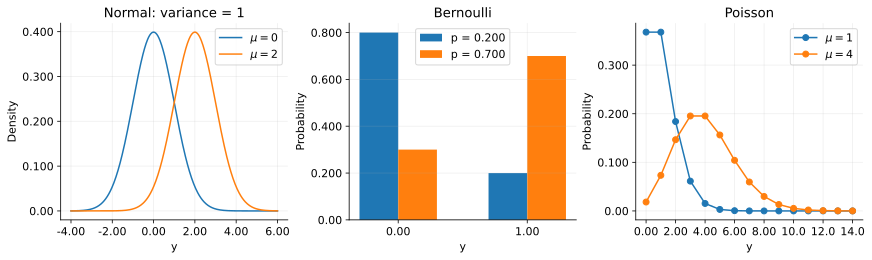

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.50), layout='constrained')
grid = np.linspace(-4, 6, 400)
for mu in (0, 2):
    axes[0].plot(grid, norm.pdf(grid, loc=mu), label=rf'$\mu={mu}$')
axes[0].set(title='Normal: variance = 1', xlabel='y', ylabel='Density')

for p, shift in ((0.200, -0.150), (0.700, 0.150)):
    axes[1].bar(np.array([0, 1]) + shift, bernoulli.pmf([0, 1], p),
                width=0.300, label=f'p = {sig3(p)}')
axes[1].set(title='Bernoulli', xlabel='y', ylabel='Probability', xticks=[0, 1])

counts = np.arange(15)
for mu in (1, 4):
    axes[2].plot(counts, poisson.pmf(counts, mu), 'o-', label=rf'$\mu={mu}$')
axes[2].set(title='Poisson', xlabel='y', ylabel='Probability')
axes[2].xaxis.set_major_locator(MaxNLocator(integer=True))
for ax in axes:
    ax.legend()
save_svg(fig, '01_distributions.svg')

## 3. 平均を説明変数につなぐ

観測$Y_i$は説明変数$\mathbf{x}_i$を条件として独立とし、$\mu_i=E[Y_i\mid\mathbf{x}_i]$とする。GLMではリンク関数$g$を選び、線形予測子と結ぶ。

$$
\eta_i=\mathbf{x}_i^{\mathsf T}\mathbf{\boldsymbol{\beta}},\qquad
g(\mu_i)=\eta_i.
$$

$\mathbf{x}_i$には切片用の$1$を含める。線形予測子とリンクの選択は、分布の性質に追加するモデルの仮定である。指数型分布族だけから一意には決まらない。

$b''>0$の範囲で$\theta_i=(b')^{-1}(\mu_i)$である。そこで$\eta_i=\theta_i$と置く選択を正準リンクと呼ぶ。

$$
g(\mu)=(b')^{-1}(\mu),\qquad
\mu_i=b'(\eta_i).
$$

正規分布は恒等リンク$g(\mu)=\mu$、ベルヌーイ分布はロジット$g(\mu)=\log\{\mu/(1-\mu)\}$、ポアソン分布は対数リンク$g(\mu)=\log\mu$になる。

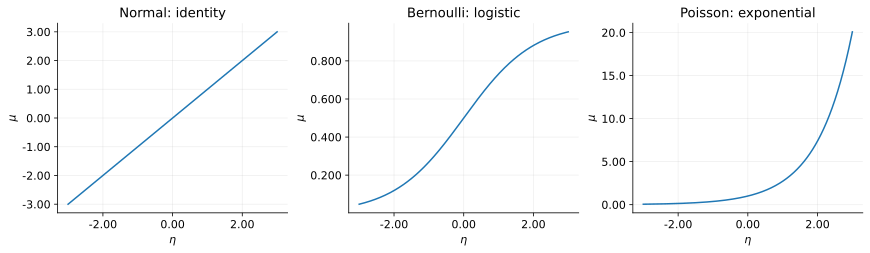

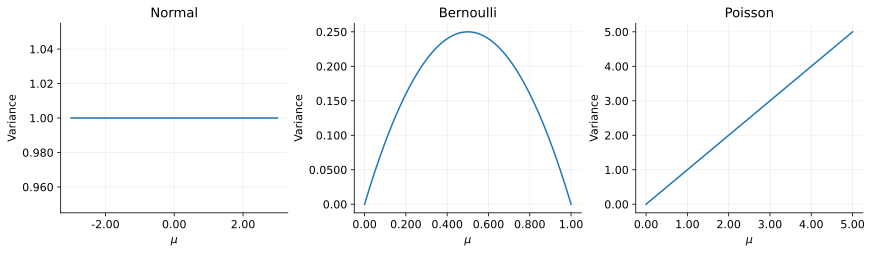

In [4]:
eta = np.linspace(-3, 3, 300)
inverse_links = [eta, expit(eta), np.exp(eta)]
titles = ['Normal: identity', 'Bernoulli: logistic', 'Poisson: exponential']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.40), layout='constrained')
for ax, mean, title in zip(axes, inverse_links, titles):
    ax.plot(eta, mean)
    ax.set(title=title, xlabel=r'$\eta$', ylabel=r'$\mu$')
save_svg(fig, '02_inverse_links.svg')

# 条件付き平均を変えたときの条件付き分散。正規分布はphi = 1。
mean_grids = [np.linspace(-3, 3, 200), np.linspace(0, 1, 200),
              np.linspace(0, 5, 200)]
variances = [np.ones(200), mean_grids[1] * (1 - mean_grids[1]), mean_grids[2]]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.40), layout='constrained')
for ax, mean, variance, title in zip(axes, mean_grids, variances, titles):
    ax.plot(mean, variance)
    ax.set(title=title.split(':')[0], xlabel=r'$\mu$', ylabel='Variance')
save_svg(fig, '03_mean_variance.svg')

## 4. 最尤推定からIRLSへ

以降は共通の$\phi$を固定し、正準リンクを使う。対数尤度を微分すると連鎖律より、

$$
\begin{aligned}
\ell(\mathbf{\boldsymbol{\beta}})&=\sum_i\left\{\frac{y_i\theta_i-b(\theta_i)}{\phi}+c(y_i,\phi)\right\},\\
\frac{\partial\ell}{\partial\beta_j}
&=\sum_i\frac{y_i-b'(\theta_i)}{\phi}\frac{\partial\theta_i}{\partial\beta_j}
=\sum_i\frac{(y_i-\mu_i)x_{ij}}{\phi},\\
\frac{\partial\mu_i}{\partial\beta_k}&=b''(\eta_i)x_{ik},\\
\frac{\partial^2\ell}{\partial\beta_j\partial\beta_k}
&=-\sum_i\frac{b''(\eta_i)x_{ij}x_{ik}}{\phi}.
\end{aligned}
$$

$\mathbf{X}$の第$i$行を$\mathbf{x}_i^{\mathsf T}$とし、$\mathbf{W}=\operatorname{diag}\{b''(\eta_i)/\phi\}$と置く。勾配$\mathbf{U}$とヘッセ行列$\mathbf{H}$は、

$$
\mathbf{U}=\mathbf{X}^{\mathsf T}(\mathbf{y}-\mathbf{\boldsymbol{\mu}})/\phi,
\qquad \mathbf{H}=-\mathbf{X}^{\mathsf T}\mathbf{W}\mathbf{X}.
$$

ニュートン法の更新は$\mathbf{\boldsymbol{\beta}}_{\rm new}=\mathbf{\boldsymbol{\beta}}-\mathbf{H}^{-1}\mathbf{U}$である。作業応答$z_i$を導入すると、

$$
\begin{aligned}
z_i&=\eta_i+\frac{y_i-\mu_i}{b''(\eta_i)},\\
\mathbf{W}(\mathbf{z}-\mathbf{X}\mathbf{\boldsymbol{\beta}})&=(\mathbf{y}-\mathbf{\boldsymbol{\mu}})/\phi,\\
\mathbf{\boldsymbol{\beta}}_{\rm new}
&=\mathbf{\boldsymbol{\beta}}+(\mathbf{X}^{\mathsf T}\mathbf{W}\mathbf{X})^{-1}\mathbf{U}\\
&=(\mathbf{X}^{\mathsf T}\mathbf{W}\mathbf{X})^{-1}\mathbf{X}^{\mathsf T}\mathbf{W}\mathbf{z}.
\end{aligned}
$$

これは$\sum_i W_{ii}(z_i-\mathbf{x}_i^{\mathsf T}\mathbf{\boldsymbol{\beta}}_{\rm new})^2$を最小にする式である。平均から重みと作業応答を再計算して反復するため、IRLSと呼ばれる。逆行列の存在には$\mathbf{X}$の列が一次独立で、重みが正であることが必要である。実装では逆行列を直接計算しない。

## 5. ポアソン回帰の実装

$\mu_i=\exp(\beta_0+\beta_1x_i)$なので$b''(\eta_i)=\mu_i$、$\phi=1$である。したがって$W_{ii}=\mu_i$、$z_i=\eta_i+(y_i-\mu_i)/\mu_i$となる。真の係数を$(0.300,0.700)$として240個の観測を生成する。乱数シードは固定する。

In [5]:
rng = np.random.default_rng(102)
x = np.linspace(-2, 2, 240)
X = np.column_stack([np.ones_like(x), x])
beta_true = np.array([0.300, 0.700])
mu_true = np.exp(X @ beta_true)
y = rng.poisson(mu_true)


def poisson_nll(beta):
    # 負の対数尤度。log(y!) は gammaln(y + 1) で計算する。
    eta_now = X @ beta
    return np.sum(np.exp(eta_now) - y * eta_now + gammaln(y + 1))


def fit_poisson_irls(X, y, max_iter=50, tol=1.00e-10):
    # 初期平均を標本平均に合わせる。この例では標本平均は正である。
    beta = np.array([np.log(y.mean()), 0])
    history = [beta.copy()]
    for _ in range(max_iter):
        eta_now = X @ beta
        mu = np.exp(eta_now)
        z = eta_now + (y - mu) / mu
        sqrt_w = np.sqrt(mu)

        # sqrt(W) を掛けた最小二乗問題を解く。重み行列の生成は不要。
        beta_new = np.linalg.lstsq(
            X * sqrt_w[:, None], z * sqrt_w, rcond=None,
        )[0]
        history.append(beta_new.copy())
        if np.linalg.norm(beta_new - beta) < tol:
            return beta_new, np.asarray(history)
        beta = beta_new
    raise RuntimeError('IRLSが指定回数内で収束しなかった')


beta_hat, history = fit_poisson_irls(X, y)
mu_hat = np.exp(X @ beta_hat)

# 導出した負の対数尤度をSciPyでも最小化し、独立に照合する。
check = minimize(
    poisson_nll, np.zeros(2), method='trust-exact',
    jac=lambda beta: X.T @ (np.exp(X @ beta) - y),
    hess=lambda beta: X.T @ (np.exp(X @ beta)[:, None] * X),
    options={'gtol': 1.00e-8},
)
assert check.success, check.message
np.testing.assert_allclose(beta_hat, check.x, rtol=1.00e-7, atol=1.00e-9)
score = X.T @ (y - mu_hat)
assert np.linalg.norm(score, ord=np.inf) < 1.00e-7

pprint({'真の係数': beta_true, 'IRLS': beta_hat, 'SciPy': check.x})
pprint({'反復回数': len(history) - 1,
        '負の対数尤度': sig3(poisson_nll(beta_hat)),
        '勾配の最大絶対値': f'{np.max(np.abs(score)):.2e}',
        '係数差の最大値': f'{np.max(np.abs(beta_hat - check.x)):.2e}'})
display(Latex(
    r'\(\displaystyle \widehat{\mu}(x)=\exp('
    + sig3(beta_hat[0]) + '+' + sig3(beta_hat[1]) + r'x)\)'
))

{'IRLS': array([0.332, 0.782]),
 'SciPy': array([0.332, 0.782]),
 '真の係数': array([0.300, 0.700])}
{'係数差の最大値': '2.38e-14', '勾配の最大絶対値': '2.21e-13', '反復回数': 6, '負の対数尤度': '365'}


<IPython.core.display.Latex object>

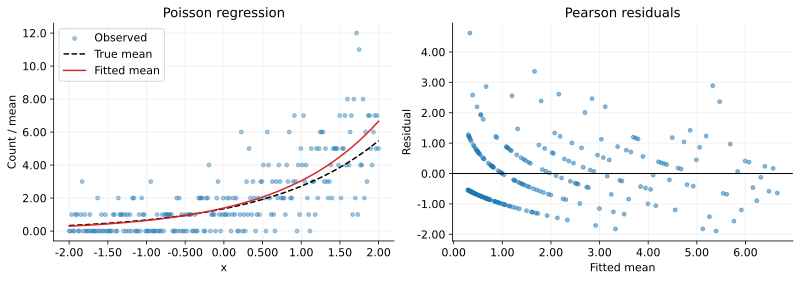

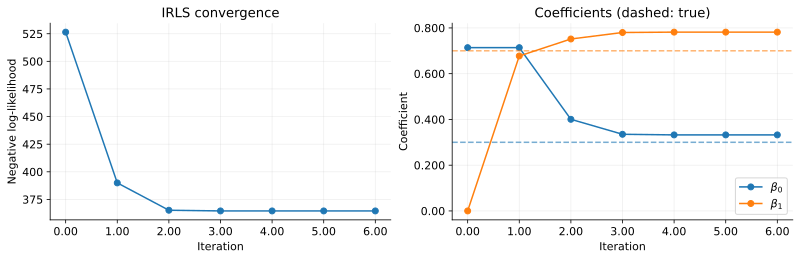

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.80), layout='constrained')
axes[0].scatter(x, y, s=15, alpha=0.400, label='Observed')
axes[0].plot(x, mu_true, '--', color='black', label='True mean')
axes[0].plot(x, mu_hat, color='tab:red', label='Fitted mean')
axes[0].set(title='Poisson regression', xlabel='x', ylabel='Count / mean')
axes[0].legend()

# Pearson残差は、分布が定める標準偏差で残差を割った値である。
pearson = (y - mu_hat) / np.sqrt(mu_hat)
axes[1].scatter(mu_hat, pearson, s=15, alpha=0.500)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set(title='Pearson residuals', xlabel='Fitted mean', ylabel='Residual')
save_svg(fig, '04_poisson_fit.svg')

iterations = np.arange(len(history))
losses = np.array([poisson_nll(beta) for beta in history])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.50), layout='constrained')
axes[0].plot(iterations, losses, 'o-')
axes[0].set(title='IRLS convergence', xlabel='Iteration', ylabel='Negative log-likelihood')
for j in range(2):
    axes[1].plot(iterations, history[:, j], 'o-', label=rf'$\beta_{j}$')
    axes[1].axhline(beta_true[j], linestyle='--', color=f'C{j}', alpha=0.600)
axes[1].set(title='Coefficients (dashed: true)', xlabel='Iteration', ylabel='Coefficient')
axes[1].legend()
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
save_svg(fig, '05_irls_convergence.svg')

実線は推定した条件付き平均であり、個々の観測が線上に並ぶわけではない。残差は$\sqrt{\widehat{\mu}_i}$で割っている。有限標本では推定係数と真の係数に差が残る。IRLSとSciPyの一致から計算を確認できる。

IRLSの収束は常に保証されるわけではない。ポアソン分布は条件付き平均と分散が等しい。実データで分散が大きい場合は、分布の選択も見直す必要がある。

## 結論

この記事では、指数型分布族の微分から平均と分散を求め、正準リンクを使うGLMの推定をIRLSとして導出した。

GLMは応答の分布、線形予測子、リンク関数で定まる。正規・ベルヌーイ・ポアソン分布は、この枠組みで線形回帰・ロジスティック回帰・ポアソン回帰につながる。

参考文献：[Andrew Ng, CS229 Lecture notes, Part III](https://see.stanford.edu/materials/aimlcs229/cs229-notes1.pdf)、[statsmodels, Generalized Linear Models](https://www.statsmodels.org/stable/glm.html)。